# PNEUMYST AI · Training

TB model first (TBX11K), NIH model 
later. Checkpoints go to `ml/checkpoints/<run_name>/` (git-ignored); rerunning a training cell resumes from `last.pt`.

In [1]:
import json, shutil, sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

from dotenv import load_dotenv
load_dotenv(REPO / ".env")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image

from ml.config import data_root
from ml.training import train as tr
from ml.training.augment import AugConfig, augment
from ml.training.data import load_processed
from ml.training.metrics import banded_auroc, binary_report, bootstrap_auroc, threshold_for_sensitivity

ROOT = data_root()
FIG = REPO / "docs" / "figures" / "training"
FIG.mkdir(parents=True, exist_ok=True)
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

torch 2.11.0+cu128 | CUDA: True | NVIDIA GeForce RTX 3050 Laptop GPU


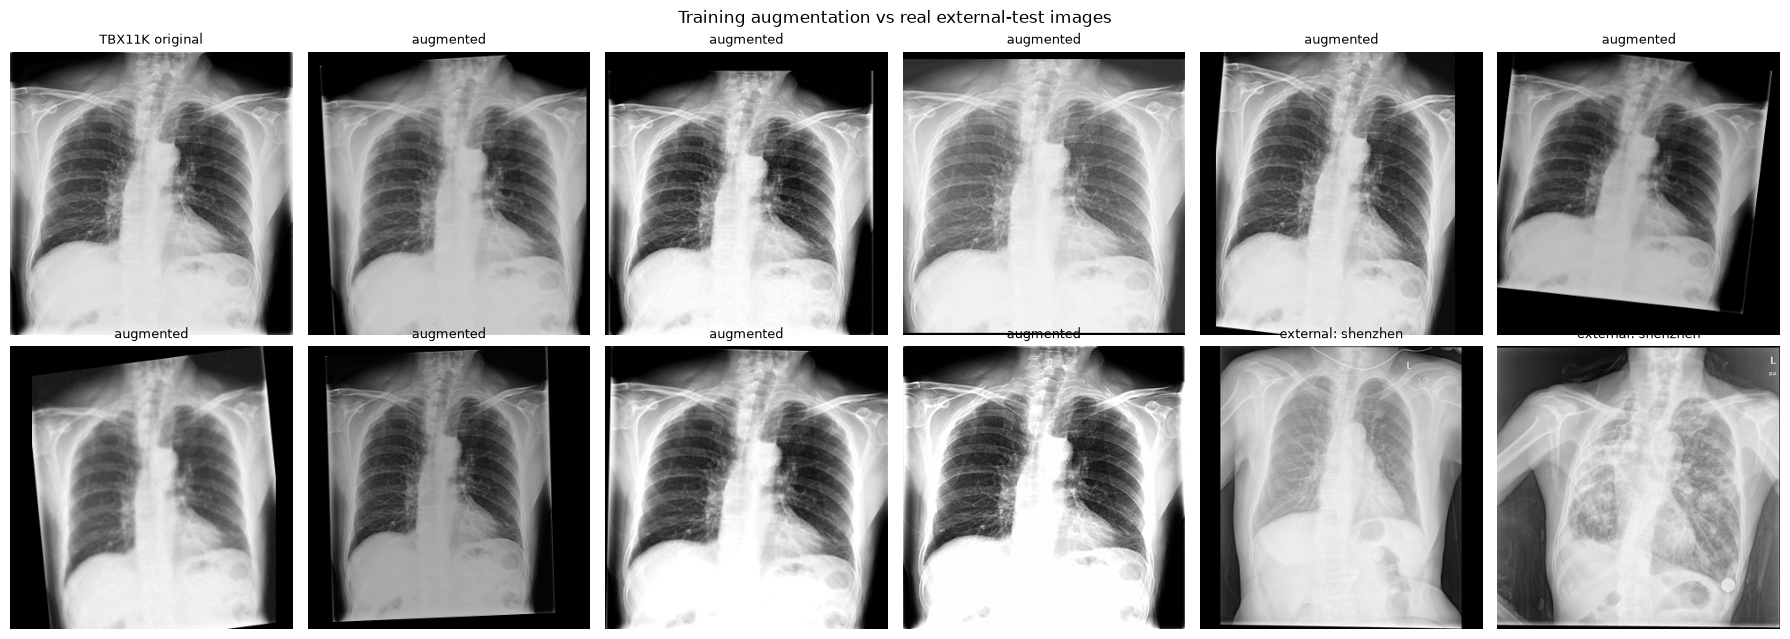

In [2]:
tbx = load_processed(ROOT, "tbx11k")
ext = pd.concat([load_processed(ROOT, s) for s in ("shenzhen", "montgomery")])
img = np.asarray(Image.open(ROOT / tbx[tbx["split"] == "train"].iloc[0]["processed_path"]))
rng = np.random.default_rng(0)
aug_cfg = AugConfig(pad_p=0.5)

fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("TBX11K original", fontsize=9)
for ax in list(axes.ravel()[1:10]):
    ax.imshow(augment(img, rng, aug_cfg), cmap="gray", vmin=0, vmax=255); ax.set_title("augmented", fontsize=9)
for ax, (_, r) in zip(axes.ravel()[10:], ext.sample(2, random_state=1).iterrows()):
    ax.imshow(np.asarray(Image.open(ROOT / r["processed_path"])), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"external: {r['source']}", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Training augmentation vs real external-test images")
plt.tight_layout(); plt.show()

In [3]:
BATCH = tr.find_batch_size(tr.TrainConfig(task="tb")) or 8
ACCUM = max(1, 32 // BATCH)   # effective batch ≈ 32
print(f"batch {BATCH} x accum {ACCUM} = effective {BATCH * ACCUM}")

batch 32: ok, peak 2.24 GB
batch 32 x accum 1 = effective 32


In [4]:
smoke_dir = REPO / "ml" / "checkpoints" / "smoke_tb"
shutil.rmtree(smoke_dir, ignore_errors=True)
smoke = tr.fit(tr.TrainConfig(task="tb", run_name="smoke_tb", epochs=2, frozen_epochs=1, batch_size=BATCH,
                              accum_steps=ACCUM, limit=256, workers=0), ROOT, run_dir=smoke_dir)
display(smoke["history"])
shutil.rmtree(smoke_dir, ignore_errors=True)

tb: train 256 | val 256 | device cuda | pos_weight [7.5]


c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\ml\training\train.py:116: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


epoch 1/2 (frozen) | train 1.3357 | val 1.2310 | metric 0.4632 | 0.72 min *best*
epoch 2/2 | train 1.2834 | val 1.0961 | metric 0.8183 | 0.11 min *best*


,epoch,frozen,train_loss,val_loss,lr_backbone,minutes,metric,auroc,auprc,auroc_sick_vs_tb
0,1,True,1.3357,1.2310,0.000100,0.72,0.463163,0.463163,0.101369,0.388618
1,2,False,1.2834,1.0961,0.000001,0.11,0.818320,0.818320,0.528993,0.719866


In [5]:
# cfg = tr.TrainConfig(task="tb", run_name="tb_densenet121_v1", epochs=20, frozen_epochs=2,
#                      batch_size=BATCH, accum_steps=ACCUM, workers=4)
# result = tr.fit(cfg, ROOT)   # if it stops, just rerun this cell: it resumes from last.pt
# RUN = result["run_dir"]
# hist = pd.read_json(RUN / "history.json")

# fig, axes = plt.subplots(1, 2, figsize=(13, 4))
# hist.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[0], title="Loss")
# hist.plot(x="epoch", y=["auroc", "auroc_sick_vs_tb", "auprc"], marker="o", ax=axes[1], title="Validation")
# plt.tight_layout(); fig.savefig(FIG / "tb_v1_curves.png", dpi=150); plt.show()
# hist  

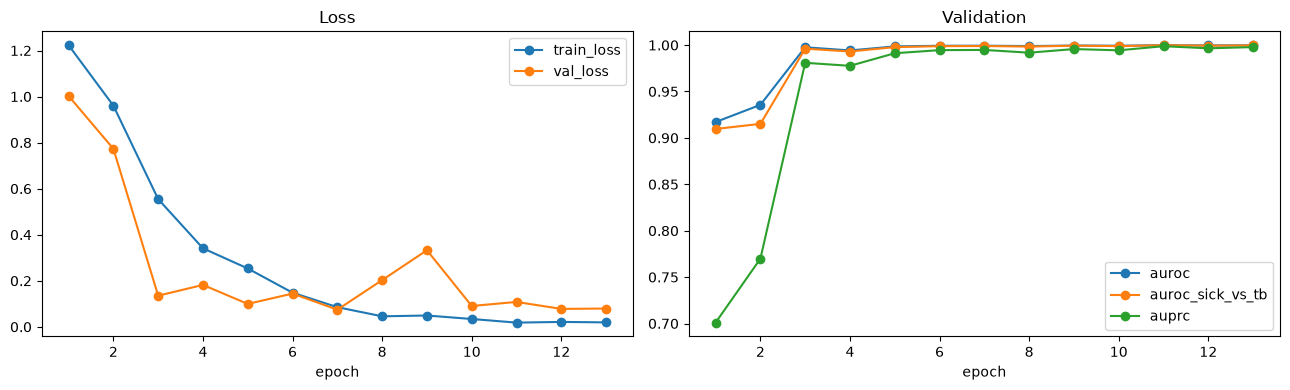

,epoch,frozen,train_loss,val_loss,lr_backbone,minutes,metric,auroc,auprc,auroc_sick_vs_tb
0,1,True,1.2230,1.0026,0.000100,1.09,0.917074,0.917074,0.700953,0.909624
1,2,True,0.9604,0.7731,0.000099,0.48,0.935613,0.935613,0.769814,0.915116
2,3,False,0.5545,0.1353,0.000097,17.08,0.997658,0.997658,0.980912,0.996135
3,4,False,0.3410,0.1820,0.000094,17.44,0.994225,0.994225,0.977666,0.993084
4,5,False,0.2534,0.0995,0.000090,16.85,0.998572,0.998572,0.991220,0.997788
5,6,False,0.1482,0.1445,0.000084,17.01,0.999286,0.999286,0.994563,0.998856
6,7,False,0.0854,0.0745,0.000078,17.13,0.999349,0.999349,0.994780,0.998983
7,8,False,0.0457,0.2029,0.000070,16.58,0.998948,0.998948,0.991811,0.998398
8,9,False,0.0492,0.3327,0.000063,16.56,0.999524,0.999524,0.995711,0.999364
9,10,False,0.0341,0.0906,0.000055,16.53,0.999324,0.999324,0.994361,0.998907


In [6]:
cfg = tr.TrainConfig(task="tb", run_name="tb_densenet121_v1")
RUN = REPO / "ml" / "checkpoints" / cfg.run_name
hist = pd.read_json(RUN / "history.json")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hist.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[0], title="Loss")
hist.plot(x="epoch", y=["auroc", "auroc_sick_vs_tb", "auprc"], marker="o", ax=axes[1], title="Validation")
plt.tight_layout(); fig.savefig(FIG / "tb_v1_curves.png", dpi=150); plt.show()
hist

In [7]:
val = pd.read_csv(RUN / "val_predictions.csv").merge(
    tbx[["image_id", "original_label", "px_sharpness", "px_mean"]], on="image_id")
y, p = val["label_tuberculosis"].to_numpy(), val["prob_tuberculosis"].to_numpy()
hard = val["original_label"].isin(["sick", "tb"]).to_numpy()

auc, lo, hi = bootstrap_auroc(y, p)
thr = threshold_for_sensitivity(y, p, 0.90)
report = binary_report(y, p, thr)
sick_vs_tb = binary_report(y[hard], p[hard], thr)["auroc"]
print(f"AUROC {auc:.3f} (95% CI {lo:.3f}-{hi:.3f}) | sick vs TB AUROC {sick_vs_tb:.3f} | threshold @90% sens {thr:.3f}")
display(pd.Series(report).to_frame("at threshold").T.round(3))

print("Score by original class:")
display(val.groupby("original_label")["prob_tuberculosis"].describe().round(3))

print("Shortcut check: AUROC inside sharpness / brightness bands (should stay close to overall):")
bands = pd.concat({"sharpness": banded_auroc(y, p, val["px_sharpness"]), "brightness": banded_auroc(y, p, val["px_mean"])})
display(bands.round(3))

summary = {"run": cfg.run_name, "best_epoch": int(hist.loc[hist["auroc"].idxmax(), "epoch"]),
           "auroc": auc, "auroc_ci": [lo, hi], "auroc_sick_vs_tb": sick_vs_tb, "threshold_90_sens": thr,
           "at_threshold": report, "bands": bands.reset_index(level=0).rename(columns={"level_0": "stat"}).to_dict("records")}
(FIG / "tb_v1_val_summary.json").write_text(json.dumps(summary, indent=2, default=str))

AUROC 1.000 (95% CI 1.000-1.000) | sick vs TB AUROC 1.000 | threshold @90% sens 0.987


,n,positives,threshold,auroc,auprc,sensitivity,specificity,ppv,npv,f1,tp,fp,tn,fn
at threshold,977.0,90.0,0.987,1.0,0.999,0.911,1.0,1.0,0.991,0.953,82.0,0.0,887.0,8.0


Score by original class:


,count,mean,std,min,25%,50%,75%,max
original_label,,,,,,,,
health,450.0,0.002,0.036,0.000,0.0,0.0,0.0,0.758
sick,437.0,0.001,0.006,0.000,0.0,0.0,0.0,0.112
tb,90.0,0.958,0.178,0.008,1.0,1.0,1.0,1.000


Shortcut check: AUROC inside sharpness / brightness bands (should stay close to overall):


band    n  positives  auroc
sharpness  0  (34.833000000000006, 86.701]  326          4  1.000
           1             (86.701, 122.758]  325         12  1.000
           2            (122.758, 542.221]  326         74  1.000
brightness 0  (66.54899999999999, 125.784]  326         22  0.999
           1            (125.784, 145.198]  325         50  1.000
           2            (145.198, 198.898]  326         18  1.000

1441

,kind,image_id,original_label,original_subtypes,prob_tuberculosis
0,missed TB,tbx11k:tb/tb0409.png,tb,ActiveTuberculosis,0.933
1,missed TB,tbx11k:tb/tb0608.png,tb,ActiveTuberculosis,0.890
2,missed TB,tbx11k:tb/tb0616.png,tb,ActiveTuberculosis,0.127
3,missed TB,tbx11k:tb/tb0688.png,tb,ActiveTuberculosis,0.008
4,missed TB,tbx11k:tb/tb0920.png,tb,ActiveTuberculosis,0.398
5,missed TB,tbx11k:tb/tb0983.png,tb,ActiveTuberculosis,0.900
6,missed TB,tbx11k:tb/tb1018.png,tb,ActiveTuberculosis,0.927
7,missed TB,tbx11k:tb/tb1179.png,tb,ObsoletePulmonaryTuberculosis,0.083
8,highest non-TB,tbx11k:health/h3716.png,health,NaN,0.758
9,highest non-TB,tbx11k:sick/s0036.png,sick,NaN,0.112


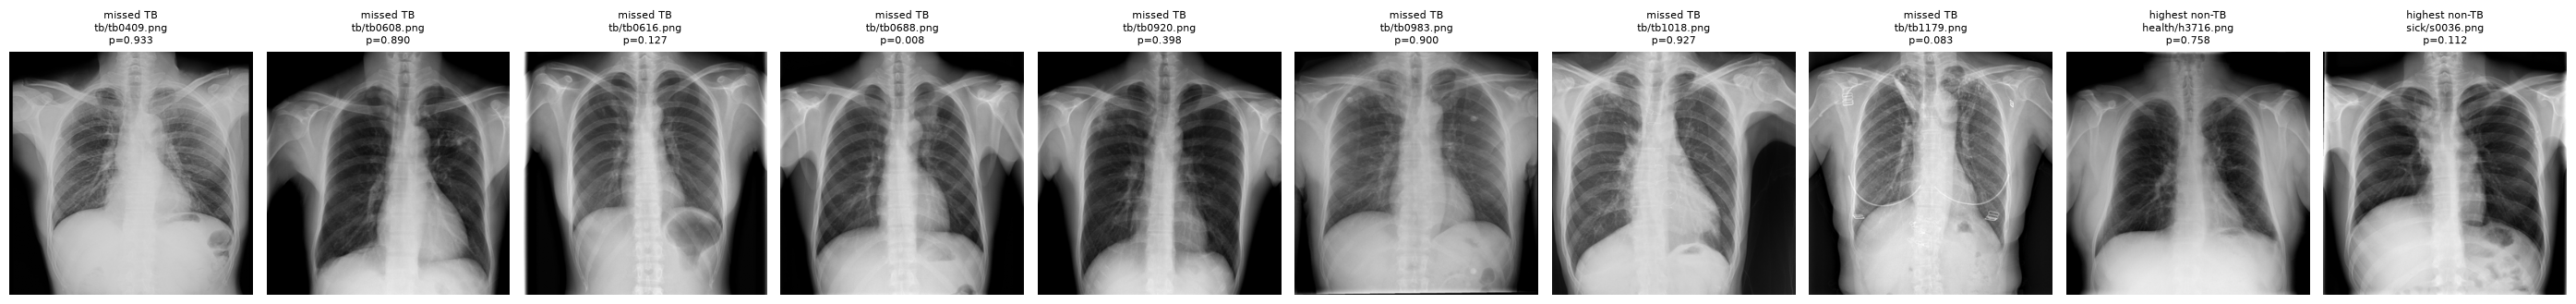

In [8]:
paths = tbx.set_index("image_id")["processed_path"]
look = pd.concat([
    val[(val["label_tuberculosis"] == 1) & (val["prob_tuberculosis"] < thr)].assign(kind="missed TB"),
    val[(val["label_tuberculosis"] == 0)].nlargest(2, "prob_tuberculosis").assign(kind="highest non-TB"),
]).merge(tbx[["image_id", "original_subtypes"]], on="image_id")
display(look[["kind", "image_id", "original_label", "original_subtypes", "prob_tuberculosis"]].round(3))
fig, axes = plt.subplots(1, len(look), figsize=(2.8 * len(look), 3.4), squeeze=False)
for ax, r in zip(axes[0], look.itertuples()):
    ax.imshow(np.asarray(Image.open(ROOT / paths[r.image_id])), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{r.kind}\n{r.image_id.split(':')[1]}\np={r.prob_tuberculosis:.3f}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

best.pt = epoch 11 | thresholds {'val_90_sens': 0.987, 'fixed_0.5': 0.5}


,set,threshold,auroc,ci_low,ci_high,n,positives,sensitivity,specificity,ppv,npv,tp,fn,fp
0,tbx11k_test,val_90_sens,0.998,0.995,1.000,1792,200,0.865,0.999,0.994,0.983,173,27,1
1,tbx11k_test,fixed_0.5,0.998,0.995,1.000,1792,200,0.920,0.999,0.989,0.990,184,16,2
2,shenzhen,val_90_sens,0.808,0.775,0.838,662,336,0.682,0.752,0.739,0.696,229,107,81
3,shenzhen,fixed_0.5,0.808,0.775,0.838,662,336,0.949,0.322,0.591,0.861,319,17,221
4,montgomery,val_90_sens,0.666,0.569,0.759,138,58,0.310,0.900,0.692,0.643,18,40,8
5,montgomery,fixed_0.5,0.666,0.569,0.759,138,58,0.569,0.662,0.550,0.679,33,25,27
6,external_combined,val_90_sens,0.782,0.751,0.814,800,394,0.627,0.781,0.735,0.683,247,147,89
7,external_combined,fixed_0.5,0.782,0.751,0.814,800,394,0.893,0.389,0.587,0.790,352,42,248


,n,positives,auroc
adults,752.0,383.0,0.775
children,48.0,11.0,0.889


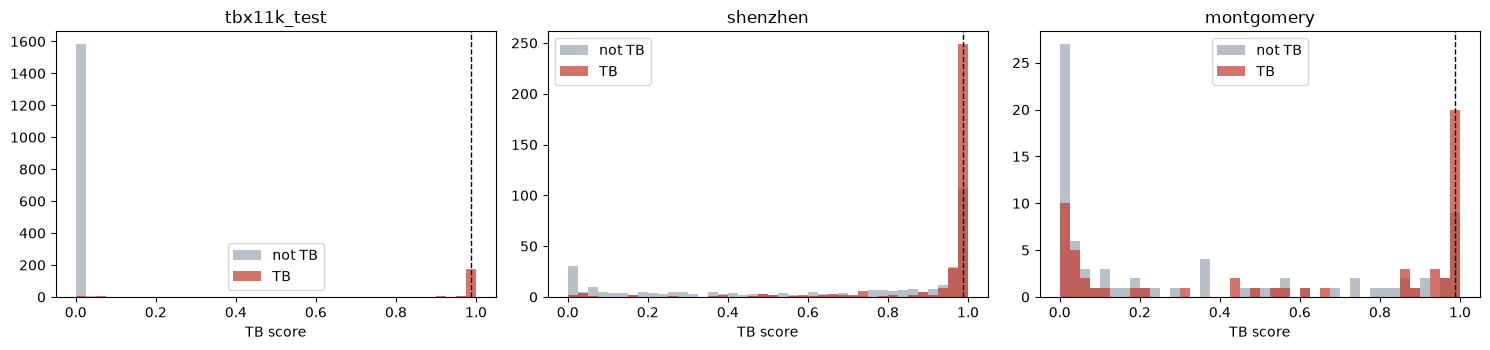

3377

In [9]:
from torch.utils.data import DataLoader
from ml.training.data import XrayDataset
from ml.training.metrics import safe_auroc
from ml.training.model import build_model

THRESHOLDS = {"val_90_sens": thr, "fixed_0.5": 0.5}   # frozen BEFORE looking at any test result
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = torch.load(RUN / "best.pt", map_location=dev, weights_only=False)
model = build_model(1, pretrained=False, memory_efficient=False).to(dev, memory_format=torch.channels_last)
model.load_state_dict(ckpt["model"])
print(f"best.pt = epoch {ckpt['epoch']} | thresholds {({k: round(v, 3) for k, v in THRESHOLDS.items()})}")

def predict_df(df: pd.DataFrame) -> pd.DataFrame:
    df = df.reset_index(drop=True)
    dl = DataLoader(XrayDataset(df, ROOT, ["label_tuberculosis"]), batch_size=32, num_workers=0)
    return df.assign(prob_tuberculosis=tr.predict(model, dl, dev)[:, 0])

preds = {"tbx11k_test": predict_df(tbx[tbx["split"] == "test"]),
         "shenzhen": predict_df(load_processed(ROOT, "shenzhen")),
         "montgomery": predict_df(load_processed(ROOT, "montgomery"))}
preds["external_combined"] = pd.concat([preds["shenzhen"], preds["montgomery"]], ignore_index=True)

rows = []
for name, d in preds.items():
    y, p = d["label_tuberculosis"].to_numpy(), d["prob_tuberculosis"].to_numpy()
    auc, lo, hi = bootstrap_auroc(y, p)
    for tname, t in THRESHOLDS.items():
        r = binary_report(y, p, t)
        rows.append({"set": name, "threshold": tname, "auroc": auc, "ci_low": lo, "ci_high": hi,
                     **{k: r[k] for k in ("n", "positives", "sensitivity", "specificity", "ppv", "npv", "tp", "fn", "fp")}})
results = pd.DataFrame(rows)
display(results.round(3))

ext = preds["external_combined"]
kids = ext["notes"].fillna("").str.contains("pediatric")
display(pd.DataFrame({grp: {"n": int(m.sum()), "positives": int(ext.loc[m, "label_tuberculosis"].sum()),
                            "auroc": safe_auroc(ext.loc[m, "label_tuberculosis"], ext.loc[m, "prob_tuberculosis"])}
                      for grp, m in {"adults": ~kids, "children": kids}.items()}).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, name in zip(axes, ["tbx11k_test", "shenzhen", "montgomery"]):
    d = preds[name]
    for lab, color in ((0, "#9aa5b1"), (1, "#c0392b")):
        ax.hist(d.loc[d["label_tuberculosis"] == lab, "prob_tuberculosis"], bins=40, range=(0, 1), alpha=0.7,
                color=color, label="TB" if lab else "not TB")
    ax.axvline(thr, color="black", linestyle="--", linewidth=1)
    ax.set_title(name); ax.set_xlabel("TB score"); ax.legend()
plt.tight_layout(); fig.savefig(FIG / "tb_v1_test_scores.png", dpi=150); plt.show()

pd.concat([d.assign(set=k) for k, d in preds.items() if k != "external_combined"])[
    ["set", "image_id", "label_tuberculosis", "prob_tuberculosis"]].to_csv(RUN / "test_predictions.csv", index=False)
(FIG / "tb_v1_test_summary.json").write_text(json.dumps(
    {"best_epoch": ckpt["epoch"], "thresholds": THRESHOLDS, "results": results.to_dict("records")}, indent=2, default=str))

In [10]:
speed = tr.benchmark_speed([
    {"batch_size": 32, "memory_efficient": True},    # what TB v1 used
    {"batch_size": 16, "memory_efficient": True},
    {"batch_size": 16, "memory_efficient": False},
    {"batch_size": 24, "memory_efficient": False},
])
speed

batch 32 | memory_efficient  True | 75.4 img/s | peak 2.35 GB | ok
batch 16 | memory_efficient  True | 65.0 img/s | peak 1.28 GB | ok
batch 16 | memory_efficient False | 84.0 img/s | peak 2.39 GB | ok
batch 24 | memory_efficient False | 54.0 img/s | peak 3.47 GB | ok


,batch_size,memory_efficient,images_per_s,peak_gb,status
0,32,True,75.4,2.35,ok
1,16,True,65.0,1.28,ok
2,16,False,84.0,2.39,ok
3,24,False,54.0,3.47,ok


In [11]:
import time
import torch.nn.functional as F
from ml.training.model import build_model

def quick_speed(channels_last: bool, amp: bool, bs: int = 16, steps: int = 10) -> dict:
    dev = torch.device("cuda")
    fmt = torch.channels_last if channels_last else torch.contiguous_format
    model = build_model(14, pretrained=False, memory_efficient=False).to(dev, memory_format=fmt)
    opt = torch.optim.AdamW(model.parameters())
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    x = torch.randn(bs, 3, 320, 320, device=dev).to(memory_format=fmt)
    y = torch.randint(0, 2, (bs, 14), device=dev).float()

    def step(train: bool) -> None:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
            out = model(x)
        if train:
            scaler.scale(F.binary_cross_entropy_with_logits(out.float(), y)).backward()
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)

    res = {}
    for name, train, ctx in (("forward_img_s", False, torch.no_grad), ("train_img_s", True, torch.enable_grad)):
        with ctx():
            for _ in range(3):
                step(train)
            torch.cuda.synchronize()
            t0 = time.time()
            for _ in range(steps):
                step(train)
            torch.cuda.synchronize()
        res[name] = round(steps * bs / (time.time() - t0), 1)
    del model, opt, x, y
    torch.cuda.empty_cache()
    return res

rows = []
for cl in (True, False):
    for amp in (True, False):
        rows.append({"channels_last": cl, "amp": amp, **quick_speed(cl, amp)})
        print(rows[-1])
pd.DataFrame(rows)

{'channels_last': True, 'amp': True, 'forward_img_s': 20.8, 'train_img_s': 8.3}
{'channels_last': True, 'amp': False, 'forward_img_s': 18.1, 'train_img_s': 0.3}
{'channels_last': False, 'amp': True, 'forward_img_s': 215.8, 'train_img_s': 71.6}


KeyboardInterrupt: 

In [12]:
BATCH, MEM_EFF = 16, False      # ← set these from the benchmark
ACCUM = max(1, 32 // BATCH)     # effective batch ≈ 32

smoke_dir = REPO / "ml" / "checkpoints" / "smoke_nih"
shutil.rmtree(smoke_dir, ignore_errors=True)
smoke = tr.fit(tr.TrainConfig(task="nih", run_name="smoke_nih", epochs=2, frozen_epochs=1, batch_size=BATCH,
                              accum_steps=ACCUM, memory_efficient=MEM_EFF, limit=512, workers=4),
               ROOT, run_dir=smoke_dir)
display(smoke["history"][["epoch", "frozen", "train_loss", "val_loss", "mean_auroc", "minutes"]])
shutil.rmtree(smoke_dir, ignore_errors=True)

nih: train 512 | val 512 | device cuda | pos_weight [9.899999618530273, 50.0, 24.600000381469727, 50.0, 9.399999618530273, 50.0, 50.0, 50.0, 4.599999904632568, 18.0, 23.399999618530273, 22.299999237060547, 50.0, 50.0]
epoch 1/2 (frozen) | train 1.1701 | val 1.1987 | metric 0.4847 | 0.25 min *best*
epoch 2/2 | train 1.1802 | val 1.3184 | metric 0.5064 | 0.17 min *best*


,epoch,frozen,train_loss,val_loss,mean_auroc,minutes
0,1,True,1.1701,1.1987,0.484652,0.25
1,2,False,1.1802,1.3184,0.506416,0.17


In [13]:
nih_cfg = tr.TrainConfig(task="nih", run_name="nih_densenet121_v1", epochs=10, frozen_epochs=1,
                         batch_size=BATCH, accum_steps=ACCUM, memory_efficient=MEM_EFF, workers=4, patience=3)
nih_result = tr.fit(nih_cfg, ROOT)   # if it stops, rerun this cell: it resumes from last.pt

nih: train 77,335 | val 9,170 | device cuda | pos_weight [9.600000381469727, 49.599998474121094, 29.399999618530273, 50.0, 9.0, 50.0, 50.0, 50.0, 5.300000190734863, 20.399999618530273, 17.5, 37.29999923706055, 50.0, 32.400001525878906]
resumed from epoch 1 (best 0.7191)
epoch 2/10 | train 1.0056 | val 0.9544 | metric 0.7893 | 19.54 min *best*
epoch 3/10 | train 0.9141 | val 0.9409 | metric 0.8040 | 19.11 min *best*
epoch 4/10 | train 0.8613 | val 0.9034 | metric 0.8163 | 18.68 min *best*
epoch 5/10 | train 0.8165 | val 0.8962 | metric 0.8229 | 18.9 min *best*
epoch 6/10 | train 0.7610 | val 0.9185 | metric 0.8283 | 18.81 min *best*
epoch 7/10 | train 0.7052 | val 0.9373 | metric 0.8285 | 18.96 min *best*
epoch 8/10 | train 0.6525 | val 1.0028 | metric 0.8243 | 19.09 min
epoch 9/10 | train 0.6057 | val 1.0973 | metric 0.8232 | 19.02 min
epoch 10/10 | train 0.5809 | val 1.1105 | metric 0.8227 | 19.26 min
early stop: no improvement for 3 epochs


best epoch 7 | mean AUROC 0.829 | padded images in val: 11.7% | AP share: 36.1%


,finding,val_positives,auroc,ci_low,ci_high,auprc,prevalence,auroc_AP,auroc_PA,auroc_padded,auroc_unpadded
0,Cardiomegaly,179,0.912,0.894,0.927,0.220,0.020,0.858,0.935,0.874,0.916
1,Effusion,951,0.898,0.888,0.907,0.515,0.104,0.873,0.910,0.920,0.895
2,Emphysema,127,0.895,0.861,0.921,0.257,0.014,0.922,0.879,0.849,0.901
3,Edema,148,0.883,0.856,0.909,0.145,0.016,0.837,0.781,0.907,0.880
4,Mass,418,0.849,0.826,0.868,0.339,0.046,0.808,0.868,0.756,0.860
5,Hernia,15,0.847,0.666,0.969,0.169,0.002,0.786,0.894,0.883,0.837
6,Pneumothorax,320,0.842,0.821,0.862,0.196,0.035,0.799,0.863,0.821,0.844
7,Atelectasis,950,0.820,0.807,0.832,0.359,0.104,0.772,0.843,0.816,0.821
8,Consolidation,307,0.813,0.794,0.835,0.142,0.033,0.773,0.806,0.850,0.808
9,Fibrosis,113,0.797,0.754,0.839,0.082,0.012,0.807,0.767,0.870,0.787


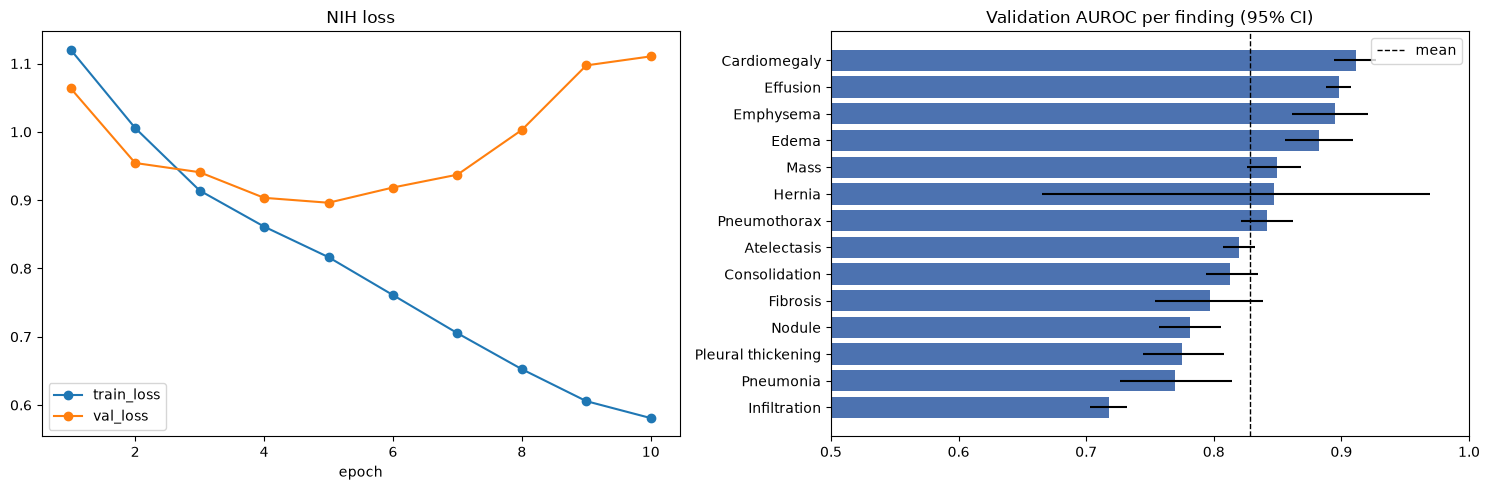

5951

In [14]:
from ml.datasets.targets import DISPLAY_NAMES, NIH_FINDINGS, label_column
from ml.training.metrics import safe_auprc, safe_auroc

NIH_RUN = REPO / "ml" / "checkpoints" / "nih_densenet121_v1"
nih_hist = pd.read_json(NIH_RUN / "history.json")
nih = load_processed(ROOT, "nih")
nv = pd.read_csv(NIH_RUN / "val_predictions.csv").merge(
    nih[["image_id", "view", "pad_left", "pad_top"]], on="image_id")
nv["padded"] = (nv["pad_left"] > 0) | (nv["pad_top"] > 0)
ap, pa, pad = (nv["view"] == "AP").to_numpy(), (nv["view"] == "PA").to_numpy(), nv["padded"].to_numpy()

rows = []
for f in NIH_FINDINGS:
    y, p = nv[label_column(f)].to_numpy(), nv[label_column(f).replace("label_", "prob_")].to_numpy()
    auc, lo, hi = bootstrap_auroc(y, p, n=500)
    rows.append({"finding": DISPLAY_NAMES[f], "val_positives": int(y.sum()), "auroc": auc, "ci_low": lo, "ci_high": hi,
                 "auprc": safe_auprc(y, p), "prevalence": y.mean(),
                 "auroc_AP": safe_auroc(y[ap], p[ap]), "auroc_PA": safe_auroc(y[pa], p[pa]),
                 "auroc_padded": safe_auroc(y[pad], p[pad]), "auroc_unpadded": safe_auroc(y[~pad], p[~pad])})
per = pd.DataFrame(rows).sort_values("auroc", ascending=False).reset_index(drop=True)
best_epoch = int(nih_hist.loc[nih_hist["metric"].idxmax(), "epoch"])
print(f"best epoch {best_epoch} | mean AUROC {per['auroc'].mean():.3f} | "
      f"padded images in val: {pad.mean():.1%} | AP share: {ap.mean():.1%}")
display(per.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
nih_hist.plot(x="epoch", y=["train_loss", "val_loss"], marker="o", ax=axes[0], title="NIH loss")
axes[1].barh(per["finding"][::-1], per["auroc"][::-1], color="#4c72b0",
             xerr=[(per["auroc"] - per["ci_low"])[::-1], (per["ci_high"] - per["auroc"])[::-1]])
axes[1].axvline(per["auroc"].mean(), color="black", linestyle="--", linewidth=1, label="mean")
axes[1].set_xlim(0.5, 1.0)
axes[1].set_title("Validation AUROC per finding (95% CI)")
axes[1].legend()
plt.tight_layout(); fig.savefig(FIG / "nih_v1_val_per_finding.png", dpi=150); plt.show()

(FIG / "nih_v1_val_summary.json").write_text(json.dumps(
    {"run": "nih_densenet121_v1", "best_epoch": best_epoch, "mean_auroc": float(per["auroc"].mean()),
     "per_finding": per.to_dict("records")}, indent=2, default=str))

,finding,val_positives,prevalence,mean_raw_score,mean_calibrated,ece_raw,ece_calibrated,threshold,sensitivity,specificity,ppv,flagged_share
0,Atelectasis,950,0.104,0.342,0.104,0.238,0.004,0.055,0.901,0.542,0.185,0.504
1,Cardiomegaly,179,0.020,0.141,0.019,0.122,0.001,0.013,0.905,0.769,0.072,0.244
2,Consolidation,307,0.033,0.262,0.033,0.228,0.002,0.019,0.902,0.563,0.067,0.452
3,Edema,148,0.016,0.144,0.016,0.128,0.001,0.009,0.905,0.695,0.046,0.315
4,Effusion,951,0.104,0.284,0.104,0.181,0.011,0.070,0.900,0.739,0.285,0.327
5,Emphysema,127,0.014,0.151,0.014,0.137,0.001,0.007,0.906,0.663,0.036,0.344
6,Fibrosis,113,0.012,0.216,0.012,0.204,0.000,0.005,0.903,0.443,0.020,0.561
7,Hernia,15,0.002,0.014,0.002,0.012,0.000,0.000,0.933,0.361,0.002,0.640
8,Infiltration,1499,0.163,0.464,0.164,0.300,0.007,0.088,0.901,0.292,0.199,0.740
9,Mass,418,0.046,0.288,0.046,0.243,0.004,0.019,0.902,0.550,0.087,0.470


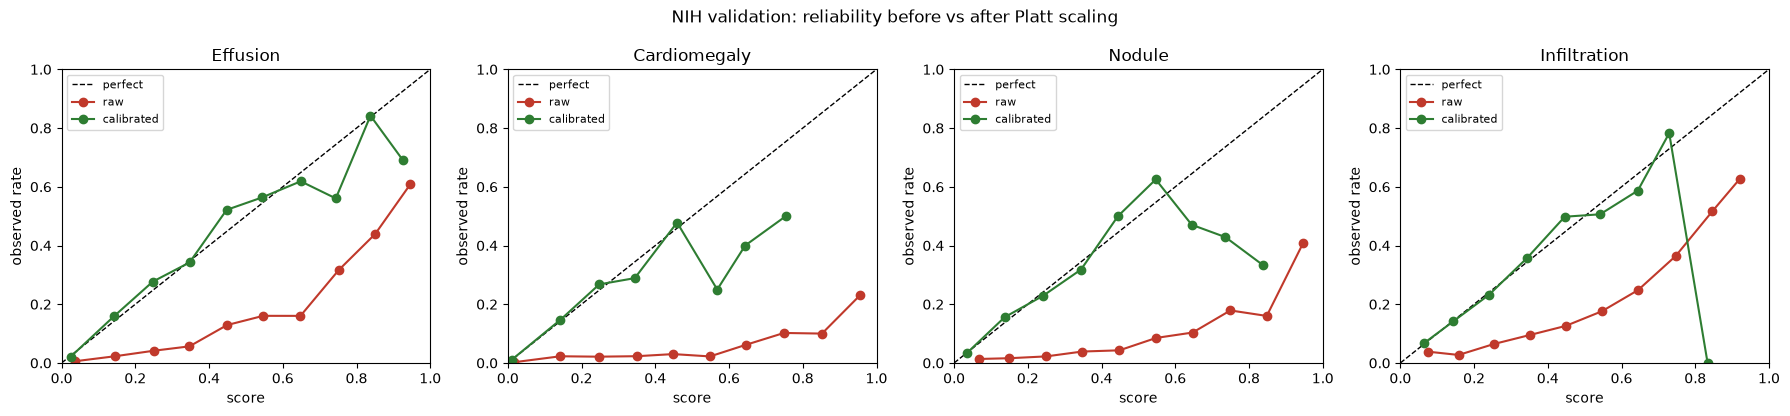

saved c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\ml\configs\nih_v1_calibration.json


In [15]:
from ml.datasets.targets import DISPLAY_NAMES, NIH_FINDINGS, label_column
from ml.evaluation.calibration import apply_platt, expected_calibration_error, fit_platt, reliability_table
from ml.training.metrics import binary_report, threshold_for_sensitivity

TARGET_SENS = 0.90   # screening: catch at least 90% of positives (validation)
NIH_RUN = REPO / "ml" / "checkpoints" / "nih_densenet121_v1"
nv = pd.read_csv(NIH_RUN / "val_predictions.csv")

cal_cfg, rows, curves = {}, [], {}
for f in NIH_FINDINGS:
    y = nv[label_column(f)].to_numpy()
    raw = nv[label_column(f).replace("label_", "prob_")].to_numpy()
    a, b = fit_platt(y, raw)
    cal = apply_platt(raw, a, b)
    thr = threshold_for_sensitivity(y, cal, TARGET_SENS)
    r = binary_report(y, cal, thr)
    cal_cfg[f] = {"platt_a": round(a, 6), "platt_b": round(b, 6), "threshold": round(thr, 6)}
    curves[f] = (reliability_table(y, raw), reliability_table(y, cal))
    rows.append({"finding": DISPLAY_NAMES[f], "val_positives": int(y.sum()), "prevalence": y.mean(),
                 "mean_raw_score": raw.mean(), "mean_calibrated": cal.mean(),
                 "ece_raw": expected_calibration_error(y, raw), "ece_calibrated": expected_calibration_error(y, cal),
                 "threshold": thr, "sensitivity": r["sensitivity"], "specificity": r["specificity"],
                 "ppv": r["ppv"], "flagged_share": float((cal >= thr).mean())})
calib = pd.DataFrame(rows)
display(calib.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, f in zip(axes, ["Effusion", "Cardiomegaly", "Nodule", "Infiltration"]):
    before, after = curves[f]
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="perfect")
    ax.plot(before["mean_score"], before["observed_rate"], "o-", color="#c0392b", label="raw")
    ax.plot(after["mean_score"], after["observed_rate"], "o-", color="#2e7d32", label="calibrated")
    ax.set_title(DISPLAY_NAMES[f]); ax.set_xlabel("score"); ax.set_ylabel("observed rate")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(fontsize=8)
fig.suptitle("NIH validation: reliability before vs after Platt scaling")
plt.tight_layout(); fig.savefig(FIG / "nih_v1_calibration.png", dpi=150); plt.show()

cfg_path = REPO / "ml" / "configs" / "nih_v1_calibration.json"
cfg_path.parent.mkdir(parents=True, exist_ok=True)
cfg_path.write_text(json.dumps({
    "model": "nih_densenet121_v1", "checkpoint": "ml/checkpoints/nih_densenet121_v1/best.pt",
    "fitted_on": f"NIH validation split ({len(nv):,} images)", "method": "platt", "target_sensitivity": TARGET_SENS,
    "findings": cal_cfg}, indent=2))
print("saved", cfg_path)

In [16]:
from ml.datasets.targets import DISPLAY_NAMES, NIH_FINDINGS, label_column
from ml.evaluation.calibration import apply_platt

TARGET_SPEC = 0.90                 # "likely" band: at most ~10% of healthy images turn red
INSUFFICIENT = {"Hernia"}          # too few validation positives (15) for any trustworthy threshold

def threshold_for_specificity(y, p, target: float) -> float:
    """Lowest threshold that keeps at least `target` of the negatives below it (positive if p >= t)."""
    neg = np.sort(p[y == 0])
    k = int(np.ceil(target * len(neg)))
    return float(np.nextafter(neg[k - 1], np.inf))

cfg_path = REPO / "ml" / "configs" / "nih_v1_calibration.json"
cfg = json.loads(cfg_path.read_text())
nv = pd.read_csv(REPO / "ml" / "checkpoints" / "nih_densenet121_v1" / "val_predictions.csv")

rows = []
for f in NIH_FINDINGS:
    c = cfg["findings"][f]
    y = nv[label_column(f)].to_numpy()
    cal = apply_platt(nv[label_column(f).replace("label_", "prob_")].to_numpy(), c["platt_a"], c["platt_b"])
    possible = c.get("possible_threshold", c.get("threshold"))
    likely = max(threshold_for_specificity(y, cal, TARGET_SPEC), possible)
    c.pop("threshold", None)
    c.update({"possible_threshold": round(possible, 6), "likely_threshold": round(likely, 6),
              "status": "insufficient_data" if f in INSUFFICIENT else "banded"})
    band = np.where(cal >= likely, "likely", np.where(cal >= possible, "possible", "unlikely"))
    pos, neg = y == 1, y == 0
    rows.append({"finding": DISPLAY_NAMES[f], "status": c["status"], "positives": int(pos.sum()),
                 "possible_thr": possible, "likely_thr": likely,
                 "all_unlikely": (band == "unlikely").mean(), "all_possible": (band == "possible").mean(),
                 "all_likely": (band == "likely").mean(),
                 "cases_caught_possible_or_likely": (band[pos] != "unlikely").mean(),
                 "cases_in_likely": (band[pos] == "likely").mean(),
                 "healthy_in_likely": (band[neg] == "likely").mean(),
                 "likely_ppv": y[band == "likely"].mean() if (band == "likely").any() else np.nan})
bands = pd.DataFrame(rows)
display(bands.round(3))

cfg.update({"target_sensitivity_possible": cfg.pop("target_sensitivity", 0.90), "target_specificity_likely": TARGET_SPEC,
            "bands": {"unlikely": "score < possible_threshold", "possible": "possible_threshold <= score < likely_threshold",
                      "likely": "score >= likely_threshold"}})
cfg_path.write_text(json.dumps(cfg, indent=2))
(FIG / "nih_v1_val_bands.json").write_text(bands.to_json(orient="records", indent=2))
print("updated", cfg_path)

,finding,status,positives,possible_thr,likely_thr,all_unlikely,all_possible,all_likely,cases_caught_possible_or_likely,cases_in_likely,healthy_in_likely,likely_ppv
0,Atelectasis,banded,950,0.055,0.222,0.496,0.365,0.139,0.900,0.475,0.1,0.354
1,Cardiomegaly,banded,179,0.013,0.041,0.756,0.132,0.112,0.899,0.726,0.1,0.126
2,Consolidation,banded,307,0.019,0.083,0.548,0.341,0.112,0.899,0.446,0.1,0.134
3,Edema,banded,148,0.009,0.040,0.685,0.205,0.109,0.905,0.682,0.1,0.101
4,Effusion,banded,951,0.070,0.206,0.673,0.167,0.161,0.899,0.686,0.1,0.443
5,Emphysema,banded,127,0.007,0.024,0.656,0.236,0.108,0.906,0.701,0.1,0.090
6,Fibrosis,banded,113,0.005,0.028,0.439,0.456,0.105,0.894,0.478,0.1,0.056
7,Hernia,insufficient_data,15,0.000,0.003,0.360,0.539,0.101,0.933,0.733,0.1,0.012
8,Infiltration,banded,1499,0.088,0.264,0.261,0.599,0.140,0.900,0.346,0.1,0.404
9,Mass,banded,418,0.019,0.083,0.530,0.346,0.124,0.900,0.634,0.1,0.232


updated c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\ml\configs\nih_v1_calibration.json


In [17]:
from torch.utils.data import DataLoader
from ml.datasets.targets import DISPLAY_NAMES, NIH_FINDINGS, label_column
from ml.evaluation.calibration import apply_platt, expected_calibration_error
from ml.training.data import XrayDataset
from ml.training.metrics import safe_auroc
from ml.training.model import build_model

cfg = json.loads((REPO / "ml" / "configs" / "nih_v1_calibration.json").read_text())   # frozen on validation
NIH_RUN = REPO / "ml" / "checkpoints" / "nih_densenet121_v1"
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = torch.load(NIH_RUN / "best.pt", map_location=dev, weights_only=False)
model = build_model(len(NIH_FINDINGS), pretrained=False, memory_efficient=False).to(dev)
model.load_state_dict(ckpt["model"])
labels = [label_column(f) for f in NIH_FINDINGS]

nih = load_processed(ROOT, "nih")
test = nih[nih["split"] == "test"].reset_index(drop=True)
probs = tr.predict(model, DataLoader(XrayDataset(test, ROOT, labels), batch_size=32, num_workers=0), dev)
print(f"best.pt = epoch {ckpt['epoch']} | test images {len(test):,} | AP share {(test['view'] == 'AP').mean():.1%}")

ap, pa = (test["view"] == "AP").to_numpy(), (test["view"] == "PA").to_numpy()
rows, out = [], test[["image_id", "view"] + labels].copy()
for i, f in enumerate(NIH_FINDINGS):
    c, y = cfg["findings"][f], test[label_column(f)].to_numpy()
    cal = apply_platt(probs[:, i], c["platt_a"], c["platt_b"])
    out[f"cal_{f.lower()}"] = cal
    band = np.where(cal >= c["likely_threshold"], "likely", np.where(cal >= c["possible_threshold"], "possible", "unlikely"))
    pos, neg = y == 1, y == 0
    auc, lo, hi = bootstrap_auroc(y, cal, n=500)
    rows.append({"finding": DISPLAY_NAMES[f], "status": c["status"], "positives": int(pos.sum()), "prevalence": y.mean(),
                 "auroc": auc, "ci_low": lo, "ci_high": hi,
                 "auroc_AP": safe_auroc(y[ap], cal[ap]), "auroc_PA": safe_auroc(y[pa], cal[pa]),
                 "mean_calibrated": cal.mean(), "ece": expected_calibration_error(y, cal),
                 "all_likely": (band == "likely").mean(), "cases_caught_possible_or_likely": (band[pos] != "unlikely").mean(),
                 "cases_in_likely": (band[pos] == "likely").mean(), "healthy_in_likely": (band[neg] == "likely").mean(),
                 "likely_ppv": y[band == "likely"].mean() if (band == "likely").any() else np.nan})
nih_test = pd.DataFrame(rows).sort_values("auroc", ascending=False).reset_index(drop=True)
val_auc = {r["finding"]: r["auroc"] for r in json.loads((FIG / "nih_v1_val_summary.json").read_text())["per_finding"]}
nih_test.insert(4, "val_auroc", nih_test["finding"].map(val_auc))
print(f"mean test AUROC {nih_test['auroc'].mean():.3f} (validation {np.mean(list(val_auc.values())):.3f})")
display(nih_test.round(3))

out.to_csv(NIH_RUN / "test_predictions.csv", index=False)
(FIG / "nih_v1_test_summary.json").write_text(json.dumps(
    {"run": "nih_densenet121_v1", "best_epoch": ckpt["epoch"], "test_images": len(test),
     "mean_auroc": float(nih_test["auroc"].mean()), "per_finding": nih_test.to_dict("records")}, indent=2, default=str))

best.pt = epoch 7 | test images 25,588 | AP share 56.6%
mean test AUROC 0.813 (validation 0.829)


,finding,status,positives,prevalence,val_auroc,auroc,ci_low,ci_high,auroc_AP,auroc_PA,mean_calibrated,ece,all_likely,cases_caught_possible_or_likely,cases_in_likely,healthy_in_likely,likely_ppv
0,Emphysema,banded,1093,0.043,0.895,0.926,0.918,0.933,0.934,0.913,0.031,0.014,0.190,0.969,0.879,0.160,0.197
1,Hernia,insufficient_data,86,0.003,0.847,0.901,0.855,0.941,0.778,0.918,0.002,0.002,0.123,0.977,0.826,0.121,0.023
2,Cardiomegaly,banded,1069,0.042,0.912,0.894,0.885,0.903,0.856,0.935,0.030,0.013,0.154,0.903,0.748,0.128,0.203
3,Pneumothorax,banded,2664,0.104,0.842,0.863,0.857,0.870,0.848,0.863,0.067,0.038,0.251,0.976,0.762,0.191,0.317
4,Edema,banded,924,0.036,0.883,0.850,0.838,0.860,0.779,0.847,0.034,0.003,0.264,0.963,0.793,0.245,0.108
5,Effusion,banded,4656,0.182,0.898,0.826,0.819,0.831,0.796,0.860,0.181,0.009,0.324,0.940,0.724,0.235,0.407
6,Mass,banded,1748,0.068,0.849,0.825,0.815,0.836,0.801,0.843,0.068,0.007,0.219,0.951,0.689,0.184,0.215
7,Fibrosis,banded,435,0.017,0.797,0.825,0.805,0.842,0.821,0.785,0.013,0.004,0.116,0.936,0.529,0.109,0.077
8,Pleural thickening,banded,1143,0.045,0.775,0.781,0.769,0.793,0.780,0.759,0.037,0.008,0.213,0.968,0.591,0.196,0.124
9,Atelectasis,banded,3278,0.128,0.820,0.772,0.765,0.780,0.761,0.788,0.129,0.008,0.164,0.943,0.440,0.124,0.343


9553

---
# TB v2: Shenzhen-dev selection, label smoothing, wider augmentation, calibration

In [2]:
split = tr.make_shenzhen_split(ROOT)          # creates ml/configs/tb_shenzhen_split.csv once; never overwrites
sz = load_processed(ROOT, "shenzhen").merge(split, on="image_id")
display(sz.groupby(["part", "label_tuberculosis"]).size().unstack().rename(columns={0: "not TB", 1: "TB"}))

label_tuberculosis,not TB,TB
part,,
dev,163,168
test,163,168


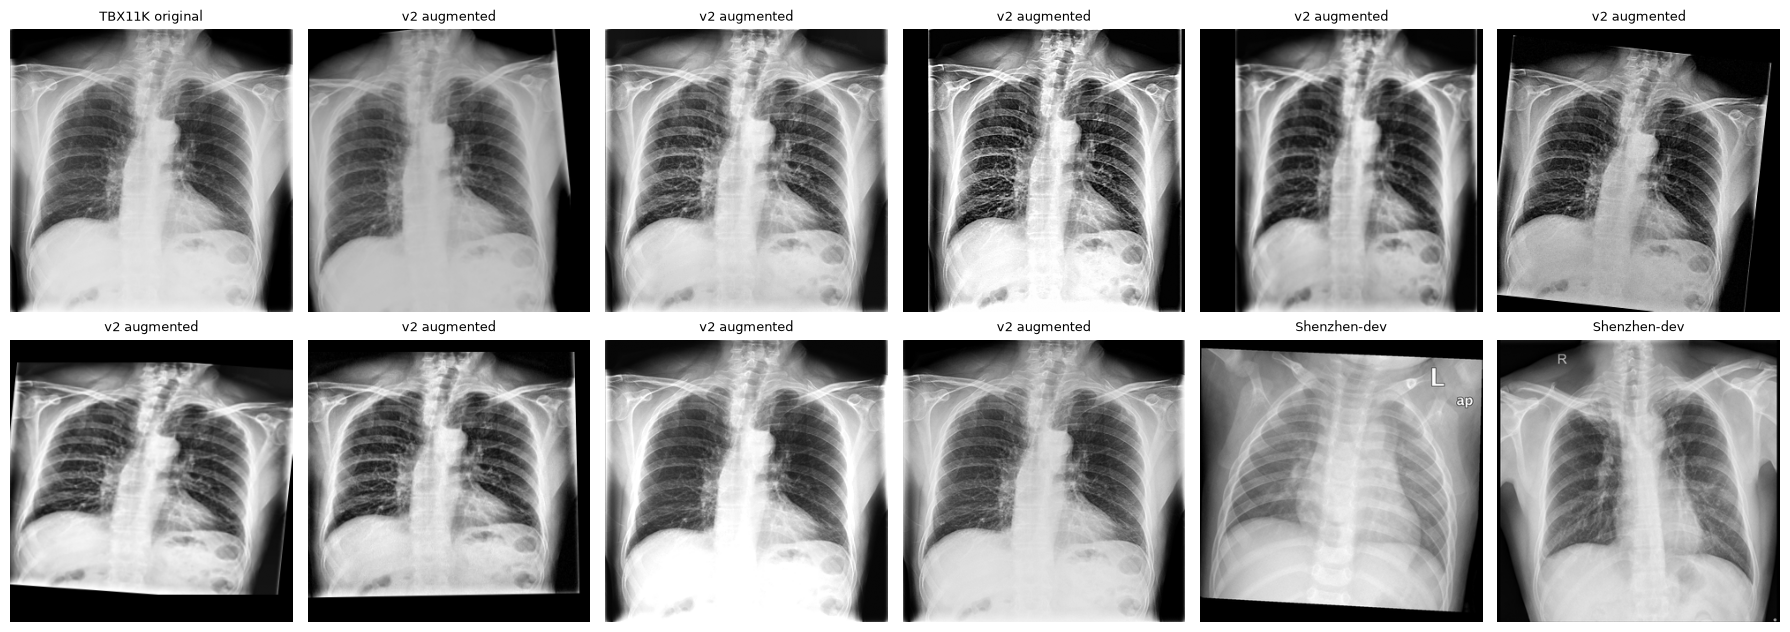

In [3]:
TB_V2_AUG = {"contrast": (0.65, 1.4), "gamma": (0.7, 1.5), "brightness": 0.15, "clahe_p": 0.3, "lowres_p": 0.3}
tbx = load_processed(ROOT, "tbx11k")
img = np.asarray(Image.open(ROOT / tbx[tbx["split"] == "train"].iloc[0]["processed_path"]))
rng = np.random.default_rng(0)
aug2 = AugConfig(pad_p=0.5, **TB_V2_AUG)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
axes[0, 0].imshow(img, cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("TBX11K original", fontsize=9)
for ax in list(axes.ravel()[1:10]):
    ax.imshow(augment(img, rng, aug2), cmap="gray", vmin=0, vmax=255); ax.set_title("v2 augmented", fontsize=9)
for ax, (_, r) in zip(axes.ravel()[10:], sz[sz["part"] == "dev"].sample(2, random_state=1).iterrows()):
    ax.imshow(np.asarray(Image.open(ROOT / r["processed_path"])), cmap="gray", vmin=0, vmax=255)
    ax.set_title("Shenzhen-dev", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

In [4]:
smoke_dir = REPO / "ml" / "checkpoints" / "smoke_tb2"
shutil.rmtree(smoke_dir, ignore_errors=True)
smoke = tr.fit(tr.TrainConfig(task="tb", run_name="smoke_tb2", epochs=2, frozen_epochs=1, batch_size=16, accum_steps=2,
                              memory_efficient=False, limit=256, workers=0, label_smoothing=0.1, aug=TB_V2_AUG,
                              dev_set="shenzhen_dev"), ROOT, run_dir=smoke_dir)
display(smoke["history"][["epoch", "frozen", "train_loss", "auroc", "dev_auroc", "minutes"]])
shutil.rmtree(smoke_dir, ignore_errors=True)

tb: train 256 | val 256 | dev 331 | device cuda | pos_weight [7.5]


c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\ml\training\train.py:155: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


epoch 1/2 (frozen) | train 1.5686 | val 1.2849 | metric 0.3803 (val auroc 0.4334) | 2.16 min *best*
epoch 2/2 | train 1.5292 | val 1.2771 | metric 0.6511 (val auroc 0.7827) | 0.37 min *best*


,epoch,frozen,train_loss,auroc,dev_auroc,minutes
0,1,True,1.5686,0.433389,0.380295,2.16
1,2,False,1.5292,0.782698,0.651147,0.37


In [5]:
tb2_cfg = tr.TrainConfig(task="tb", run_name="tb_densenet121_v2", epochs=12, frozen_epochs=2, batch_size=16, accum_steps=2,
                         memory_efficient=False, workers=4, patience=4, label_smoothing=0.1, aug=TB_V2_AUG,
                         dev_set="shenzhen_dev")
tb2 = tr.fit(tb2_cfg, ROOT)    # if it stops, rerun this cell: it resumes from last.pt
display(tb2["history"][["epoch", "frozen", "train_loss", "val_loss", "auroc", "dev_auroc", "minutes"]])

tb: train 5,479 | val 977 | dev 331 | device cuda | pos_weight [9.699999809265137]


c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\ml\training\train.py:155: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


epoch 1/12 (frozen) | train 1.4732 | val 1.1283 | metric 0.7036 (val auroc 0.9022) | 1.97 min *best*
epoch 2/12 (frozen) | train 1.3097 | val 0.8722 | metric 0.7492 (val auroc 0.9429) | 1.34 min *best*
epoch 3/12 | train 1.1675 | val 0.4840 | metric 0.8159 (val auroc 0.9959) | 4.58 min *best*
epoch 4/12 | train 1.0439 | val 0.4719 | metric 0.8455 (val auroc 0.9979) | 5.26 min *best*
epoch 5/12 | train 1.0109 | val 0.4861 | metric 0.8346 (val auroc 0.9981) | 5.35 min
epoch 6/12 | train 0.9729 | val 0.4585 | metric 0.7851 (val auroc 0.9997) | 5.36 min
epoch 7/12 | train 0.9392 | val 0.3975 | metric 0.8351 (val auroc 0.9989) | 5.37 min
epoch 8/12 | train 0.9258 | val 0.3886 | metric 0.8683 (val auroc 0.9984) | 5.37 min *best*
epoch 9/12 | train 0.9126 | val 0.4117 | metric 0.8045 (val auroc 0.9993) | 5.38 min
epoch 10/12 | train 0.9096 | val 0.4000 | metric 0.8548 (val auroc 0.9993) | 5.37 min
epoch 11/12 | train 0.9043 | val 0.4196 | metric 0.7922 (val auroc 0.9991) | 5.17 min
epoch 12/1

,epoch,frozen,train_loss,val_loss,auroc,dev_auroc,minutes
0,1,True,1.4732,1.1283,0.902242,0.703641,1.97
1,2,True,1.3097,0.8722,0.942866,0.749178,1.34
2,3,False,1.1675,0.4840,0.995941,0.815914,4.58
3,4,False,1.0439,0.4719,0.997908,0.845457,5.26
4,5,False,1.0109,0.4861,0.998071,0.834593,5.35
5,6,False,0.9729,0.4585,0.999662,0.785093,5.36
6,7,False,0.9392,0.3975,0.998923,0.835104,5.37
7,8,False,0.9258,0.3886,0.998409,0.868336,5.37
8,9,False,0.9126,0.4117,0.999311,0.804503,5.38
9,10,False,0.9096,0.4000,0.999311,0.854787,5.37


best epoch 8 | dev AUROC 0.868 | platt a=1.077 b=-2.878 | ECE raw 0.349 -> calibrated 0.077


,TB,not TB
unlikely,16,104
possible,38,43
likely,114,16


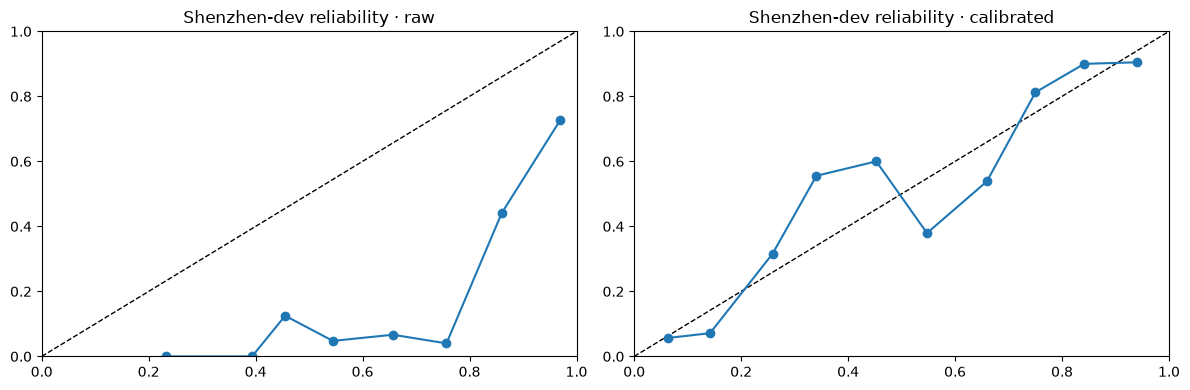

saved c:\Users\krish.LAPTOP-3EPNQNP7\Downloads\pneumyst-ai\ml\configs\tb_v2_calibration.json


In [6]:
from ml.evaluation.calibration import apply_platt, expected_calibration_error, fit_platt, reliability_table
from ml.training.metrics import safe_auroc, threshold_for_sensitivity

def threshold_for_specificity(y, p, target: float) -> float:
    neg = np.sort(p[y == 0])
    return float(np.nextafter(neg[int(np.ceil(target * len(neg))) - 1], np.inf))

TB2_RUN = REPO / "ml" / "checkpoints" / "tb_densenet121_v2"
devp = pd.read_csv(TB2_RUN / "dev_predictions.csv")
y_dev, raw_dev = devp["label_tuberculosis"].to_numpy(), devp["prob_tuberculosis"].to_numpy()
a, b = fit_platt(y_dev, raw_dev)
cal_dev = apply_platt(raw_dev, a, b)
possible = threshold_for_sensitivity(y_dev, cal_dev, 0.90)
likely = max(threshold_for_specificity(y_dev, cal_dev, 0.90), possible)
band = np.where(cal_dev >= likely, "likely", np.where(cal_dev >= possible, "possible", "unlikely"))
best_epoch = int(torch.load(TB2_RUN / "best.pt", map_location="cpu", weights_only=False)["epoch"])
print(f"best epoch {best_epoch} | dev AUROC {safe_auroc(y_dev, cal_dev):.3f} | platt a={a:.3f} b={b:.3f} | "
      f"ECE raw {expected_calibration_error(y_dev, raw_dev):.3f} -> calibrated {expected_calibration_error(y_dev, cal_dev):.3f}")
display(pd.DataFrame({b_: {"TB": int(((band == b_) & (y_dev == 1)).sum()), "not TB": int(((band == b_) & (y_dev == 0)).sum())}
                      for b_ in ("unlikely", "possible", "likely")}).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, p_) in zip(axes, (("raw", raw_dev), ("calibrated", cal_dev))):
    t = reliability_table(y_dev, p_)
    ax.plot([0, 1], [0, 1], "k--", linewidth=1); ax.plot(t["mean_score"], t["observed_rate"], "o-")
    ax.set_title(f"Shenzhen-dev reliability · {name}"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

tb2_cal_path = REPO / "ml" / "configs" / "tb_v2_calibration.json"
tb2_cal_path.write_text(json.dumps({
    "model": "tb_densenet121_v2", "checkpoint": "ml/checkpoints/tb_densenet121_v2/best.pt", "best_epoch": best_epoch,
    "fitted_on": f"Shenzhen-dev ({len(devp)} images, ml/configs/tb_shenzhen_split.csv)", "method": "platt",
    "target_sensitivity_possible": 0.90, "target_specificity_likely": 0.90,
    "findings": {"Tuberculosis": {"platt_a": round(a, 6), "platt_b": round(b, 6), "possible_threshold": round(possible, 6),
                                  "likely_threshold": round(likely, 6), "status": "banded"}}}, indent=2))
print("saved", tb2_cal_path)

,set,model,n,tb,auroc,ci_low,ci_high,ece,tb_caught,red_tb,false_red,false_red_count
0,shenzhen_test,v1,331,168,0.802,0.756,0.845,0.300,0.952,0.952,0.669,109
1,shenzhen_test,v2,331,168,0.891,0.855,0.923,0.047,0.893,0.649,0.061,10
2,montgomery,v1,138,58,0.666,0.569,0.759,0.284,0.569,0.569,0.338,27
3,montgomery,v2,138,58,0.744,0.650,0.826,0.251,0.379,0.155,0.012,1
4,tbx11k_test,v1,1792,200,0.998,0.995,1.000,0.008,0.920,0.920,0.001,2
5,tbx11k_test,v2,1792,200,0.996,0.991,0.999,0.030,0.925,0.840,0.001,1


Pre-registered rule (Montgomery): higher AUROC AND lower ECE AND no more false reds -> v2 REPLACES v1


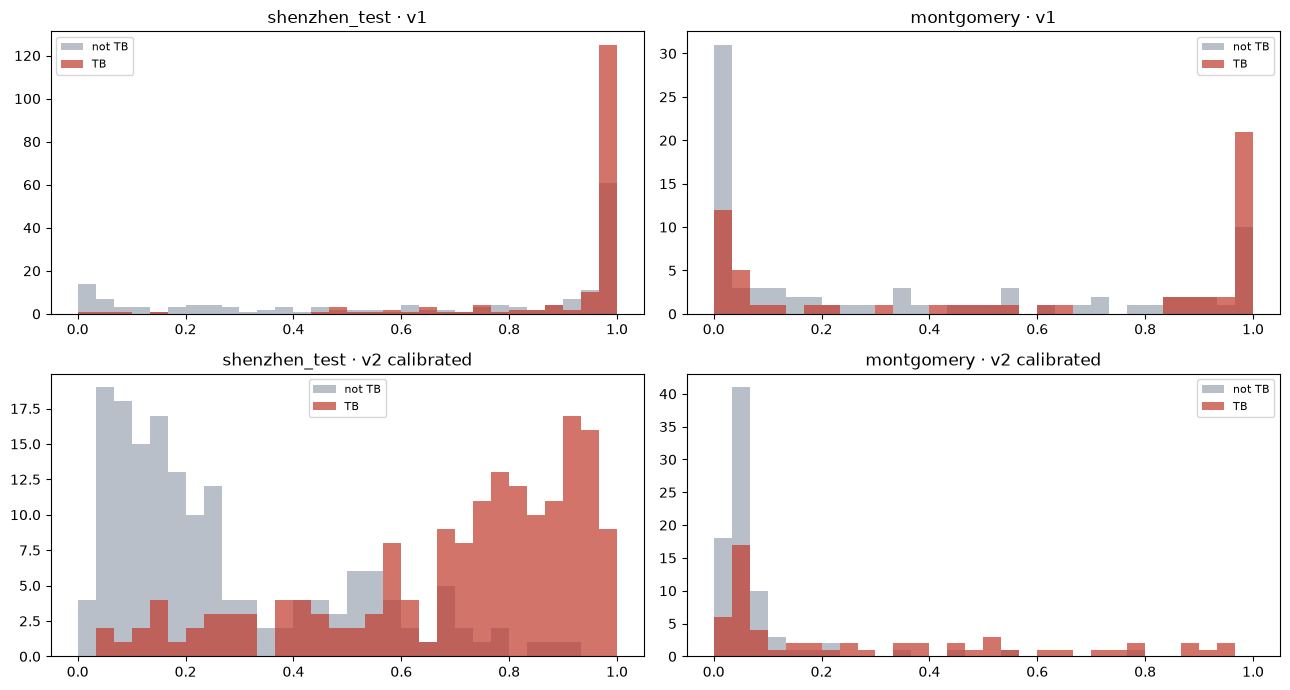

2510

In [7]:
from torch.utils.data import DataLoader
from ml.training.data import XrayDataset
from ml.training.model import build_model

c2 = json.loads(tb2_cal_path.read_text())["findings"]["Tuberculosis"]          # frozen
dev_ = torch.device("cuda" if torch.cuda.is_available() else "cpu")
m2 = build_model(1, pretrained=False, memory_efficient=False).to(dev_)
m2.load_state_dict(torch.load(TB2_RUN / "best.pt", map_location=dev_, weights_only=False)["model"])

def v2_scores(df: pd.DataFrame) -> np.ndarray:
    dl = DataLoader(XrayDataset(df.reset_index(drop=True), ROOT, ["label_tuberculosis"]), batch_size=32, num_workers=0)
    return apply_platt(tr.predict(m2, dl, dev_)[:, 0], c2["platt_a"], c2["platt_b"])

sz_test = sz[sz["part"] == "test"].reset_index(drop=True)
sets = {"shenzhen_test": sz_test, "montgomery": load_processed(ROOT, "montgomery"),
        "tbx11k_test": tbx[tbx["split"] == "test"].reset_index(drop=True)}
v1p = pd.read_csv(REPO / "ml" / "checkpoints" / "tb_densenet121_v1" / "test_predictions.csv").set_index("image_id")["prob_tuberculosis"]

rows, scores = [], {}
for name, df in sets.items():
    y = df["label_tuberculosis"].to_numpy()
    s2 = v2_scores(df)
    s1 = v1p.reindex(df["image_id"]).to_numpy()
    scores[name] = (y, s1, s2)
    for ver, s, red in (("v1", s1, s1 >= 0.5), ("v2", s2, s2 >= c2["likely_threshold"])):
        auc, lo, hi = bootstrap_auroc(y, s)
        caught = (s2 >= c2["possible_threshold"]) if ver == "v2" else red
        rows.append({"set": name, "model": ver, "n": len(y), "tb": int(y.sum()), "auroc": auc, "ci_low": lo, "ci_high": hi,
                     "ece": expected_calibration_error(y, s), "tb_caught": caught[y == 1].mean(),
                     "red_tb": red[y == 1].mean(), "false_red": red[y == 0].mean(), "false_red_count": int(red[y == 0].sum())})
cmp = pd.DataFrame(rows)
display(cmp.round(3))

mg = cmp[cmp["set"] == "montgomery"].set_index("model")
v2_wins = (mg.loc["v2", "auroc"] > mg.loc["v1", "auroc"]) and (mg.loc["v2", "ece"] < mg.loc["v1", "ece"]) \
    and (mg.loc["v2", "false_red"] <= mg.loc["v1", "false_red"])
print("Pre-registered rule (Montgomery): higher AUROC AND lower ECE AND no more false reds ->",
      "v2 REPLACES v1" if v2_wins else "KEEP v1")

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for col, name in enumerate(["shenzhen_test", "montgomery"]):
    y, s1, s2 = scores[name]
    for row_, (ver, s) in enumerate((("v1", s1), ("v2 calibrated", s2))):
        ax = axes[row_, col]
        for lab, color in ((0, "#9aa5b1"), (1, "#c0392b")):
            ax.hist(s[y == lab], bins=30, range=(0, 1), alpha=0.7, color=color, label="TB" if lab else "not TB")
        ax.set_title(f"{name} · {ver}"); ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(FIG / "tb_v1_vs_v2_scores.png", dpi=150); plt.show()
(FIG / "tb_v2_test_summary.json").write_text(json.dumps(
    {"best_epoch": best_epoch, "calibration": c2, "comparison": cmp.to_dict("records"),
     "rule": "montgomery: higher AUROC and lower ECE and no more false reds", "v2_replaces_v1": bool(v2_wins)},
    indent=2, default=str))